# Deliverable 3 — Image Captioning (CNN + RNN)

**Goal.** Write a short sentence that describes a photo, e.g. "*a man riding a wave on a surfboard*". TouNum can
then search its scanned photos by their content. This notebook is the last step of the workflow:

```txt
 image ──> [D1] photo or not? ──> [D2] denoising ──> [D3] caption (this notebook)
             not a photo: set aside
```

The complete chain, on any folder of images, is in `04_pipeline.ipynb` (used for the demo).

**Method.** We follow the tutorial **Hvass-Labs #22 "Image Captioning"**
(https://github.com/Hvass-Labs/TensorFlow-Tutorials/blob/master/22_Image_Captioning.ipynb). Two parts:
- a **CNN** (InceptionV3, already trained on ImageNet) turns each image into a vector of 2,048 numbers;
- an **RNN** (3 GRU layers) starts from this vector and writes the caption **word by word**.

Dataset: **MS COCO 2017**, about 118,000 photos with 5 human captions each.

**Differences with the tutorial**

| Hvass #22 | Here | Why |
|---|---|---|
| 118k training images | **30,000** images (90 % train, 10 % validation) | faster training |
| no test set | val2017 (5,000 images) = **test set** | honest final score |
| VGG16 (`fc2`, 4,096 numbers) | **InceptionV3** (`avg_pool`, 2,048 numbers) | more accurate on ImageNet, smaller, faster |
| pixels in [0, 1] for the CNN | the CNN's own `preprocess_input` | the input the CNN was trained with |
| `Tokenizer` (removed in Keras 3) | `TextVectorization` | Keras 3 |
| padding counted in the loss | padding **masked** | only real words count |
| no validation, 20 epochs | validation, EarlyStopping, **BLEU** score | to detect overfitting |
| greedy only | greedy **and beam search** | better sentences |

In [1]:
import tensorflow as tf, keras
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

I0000 00:00:1792413138.938879   21374 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792413139.358007   21374 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792413142.165524   21374 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1


## 1. Imports and Configuration

In [2]:
print("[Block 1] Imports and configuration : starting...")

import json, re, time, urllib.request, warnings, zipfile
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import imageio.v3 as iio          # required by the assignment (image info)
import tensorflow as tf
import keras
from keras import layers
from keras.applications import InceptionV3, VGG16, inception_v3, vgg16
from sklearn.model_selection import train_test_split
from nltk.translate.bleu_score import corpus_bleu, sentence_bleu, SmoothingFunction

warnings.filterwarnings("ignore", module="nltk")   # hide nltk BLEU warnings

# Fixed seed: same results at every run
SEED = 42
keras.utils.set_random_seed(SEED)   # Python, NumPy and TensorFlow seeds

# Paths (relative to the notebook folder, /workspace in Docker)
ROOT = Path("")
RAW = ROOT / "data_raw"            # original data
COCO = RAW / "coco"                # MS COCO 2017
DATA = ROOT / "data"               # generated files (can be deleted)
FEATURES = DATA / "coco_features"  # CNN vectors (section 3)
RESULTS = ROOT / "results"         # models, vocabulary, result tables
LOGS = RESULTS / "logs"            # training logs
for folder in (COCO, FEATURES, RESULTS, LOGS):
    folder.mkdir(parents=True, exist_ok=True)

# Data
N_TRAIN_IMAGES = 30_000   # images taken from train2017 (out of 118,287)
VAL_SHARE = 0.10          # share kept for validation

# Image preprocessing (section 3)
ENCODER = "InceptionV3"   # pretrained CNN: "InceptionV3" or "VGG16" (the tutorial's choice)
FEATURE_BATCH = 64        # batch size for the CNN

# Text preprocessing (section 4)
MARK_START, MARK_END = "ssss", "eeee"   # start / end words (from the tutorial)
NUM_WORDS = 10_000        # vocabulary size

# Network and training (values of the tutorial)
STATE_SIZE = 512          # GRU memory size
EMBEDDING_SIZE = 128      # size of a word vector
BATCH = 384               # captions per training batch
LR = 1e-3                 # learning rate of RMSprop
EPOCHS = 50               # maximum (EarlyStopping stops before)
BEAM = 3                  # beam search width

print("[Block 1] OK")

[Block 1] Imports and configuration : starting...
[Block 1] OK


## 2. The Data: MS COCO 2017

### 2.1 Download (first run only)

3 archives: annotations (250 MB), validation images (800 MB), training images (18 GB, ~30 min).
An archive already on disk is not downloaded again.

In [3]:
print("[Block 2a] Download : starting...")

COCO_URL = "http://images.cocodataset.org/"
ARCHIVES = {"annotations": "annotations/annotations_trainval2017.zip",
            "val": "zips/val2017.zip",
            "train": "zips/train2017.zip"}

def download(url_path):
    # Download an archive, unless it is already there
    dest = COCO / Path(url_path).name
    if dest.exists():
        print(f"  {dest.name}: already downloaded ({dest.stat().st_size / 1e9:.2f} GB)")
        return dest
    part = dest.with_suffix(".part")   # renamed only when complete
    def progress(blocks, block_size, total):
        print(f"\r  {dest.name}: {blocks * block_size / 1e9:.2f} / {total / 1e9:.2f} GB", end="")
    urllib.request.urlretrieve(COCO_URL + url_path, part, progress)
    part.replace(dest)
    print()
    return dest

archives = {name: download(path) for name, path in ARCHIVES.items()}

# We only need the 2 caption files
for split in ("train2017", "val2017"):
    member = f"annotations/captions_{split}.json"
    if not (COCO / member).exists():
        with zipfile.ZipFile(archives["annotations"]) as z:
            z.extract(member, COCO)
print("  caption files:", sorted(p.name for p in (COCO / "annotations").glob("captions_*.json")))

print("[Block 2a] OK")

[Block 2a] Download : starting...
  annotations_trainval2017.zip: already downloaded (0.25 GB)
  val2017.zip: already downloaded (0.82 GB)
  train2017.zip: already downloaded (19.34 GB)
  caption files: ['captions_train2017.json', 'captions_val2017.json']
[Block 2a] OK


### 2.2 The captions

The JSON files contain the images and the captions (linked by `image_id`). We build a table with one row per
image and its list of captions.

In [4]:
print("[Block 2b] Captions : starting...")

def load_coco(split):
    # One row per image, with the list of its captions
    with open(COCO / "annotations" / f"captions_{split}.json") as f:
        ann = json.load(f)
    images = pd.DataFrame(ann["images"])[["id", "file_name", "width", "height"]]
    captions = pd.DataFrame(ann["annotations"]).groupby("image_id")["caption"].apply(list)
    images["captions"] = images["id"].map(captions)
    images["path"] = [(COCO / split / f).as_posix() for f in images["file_name"]]
    return images.dropna(subset=["captions"]).sort_values("id").reset_index(drop=True)

coco_train = load_coco("train2017")
coco_test = load_coco("val2017")   # our test set

for name, table in (("train2017", coco_train), ("val2017", coco_test)):
    n_caps = table["captions"].str.len()
    print(f"  {name}: {len(table):6d} images, {n_caps.sum():6d} captions "
          f"(per image: min {n_caps.min()}, max {n_caps.max()}, mean {n_caps.mean():.2f})")
display(coco_train.head(3)[["id", "file_name", "width", "height", "captions"]])

print("[Block 2b] OK")

[Block 2b] Captions : starting...
  train2017: 118287 images, 591753 captions (per image: min 5, max 7, mean 5.00)
  val2017:   5000 images,  25014 captions (per image: min 5, max 7, mean 5.00)


,id,file_name,width,height,captions
0,9,000000000009.jpg,640,480,[Closeup of bins of food that include broccoli...
1,25,000000000025.jpg,640,426,[A giraffe eating food from the top of the tre...
2,30,000000000030.jpg,640,428,"[A flower vase is sitting on a porch stand., W..."


[Block 2b] OK


### 2.3 Subset and split

We take `N_TRAIN_IMAGES` random images and split them **by image**: the 5 captions of an image stay in the same
part (no leak between train and validation). The test set is val2017. Only the images we use are extracted.

In [5]:
print("[Block 2c] Subset, split and images : starting...")

subset = coco_train.sample(n=min(N_TRAIN_IMAGES, len(coco_train)), random_state=SEED)
train_df, val_df = train_test_split(subset, test_size=VAL_SHARE, random_state=SEED)
train_df, val_df = train_df.sort_values("id").reset_index(drop=True), val_df.sort_values("id").reset_index(drop=True)
test_df = coco_test
assert not set(train_df["id"]) & set(val_df["id"]), "the same image is in train and validation"

def extract_images(archive, split, table):
    # Extract only the missing images
    missing = [f for f in table["file_name"] if not (COCO / split / f).exists()]
    if missing:
        print(f"  {split}: extracting {len(missing)} images...")
        with zipfile.ZipFile(archive) as z:
            for f in missing:
                z.extract(f"{split}/{f}", COCO)
    print(f"  {split}: {len(table)} images on disk")

extract_images(archives["train"], "train2017", pd.concat([train_df, val_df]))
extract_images(archives["val"], "val2017", test_df)

splits = pd.DataFrame({"images": [len(train_df), len(val_df), len(test_df)],
                       "captions": [train_df.captions.str.len().sum(), val_df.captions.str.len().sum(),
                                    test_df.captions.str.len().sum()]}, index=["train", "val", "test"])
display(splits)

# Quick check with ImageIO: colour mode and size
sample = subset.sample(500, random_state=SEED)
modes = Counter(iio.immeta(p).get("mode") for p in sample["path"])
print("  colour modes (500 images):", dict(modes), "-> grey images (L) are converted to RGB")
print(f"  median size: {int(subset.width.median())} x {int(subset.height.median())} pixels")

print("[Block 2c] OK")

[Block 2c] Subset, split and images : starting...
  train2017: 30000 images on disk
  val2017: 5000 images on disk


,images,captions
train,27000,135071
val,3000,15009
test,5000,25014


  colour modes (500 images): {'RGB': 499, 'L': 1} -> grey images (L) are converted to RGB
  median size: 640 x 480 pixels
[Block 2c] OK


### 2.4 Visual inspection

The captions describe the main objects, the action and the place, always in the same simple style. The network
will learn this style, and can only describe what is common in COCO (people, animals, vehicles, food, rooms).

[Block 2d] Visual inspection : starting...


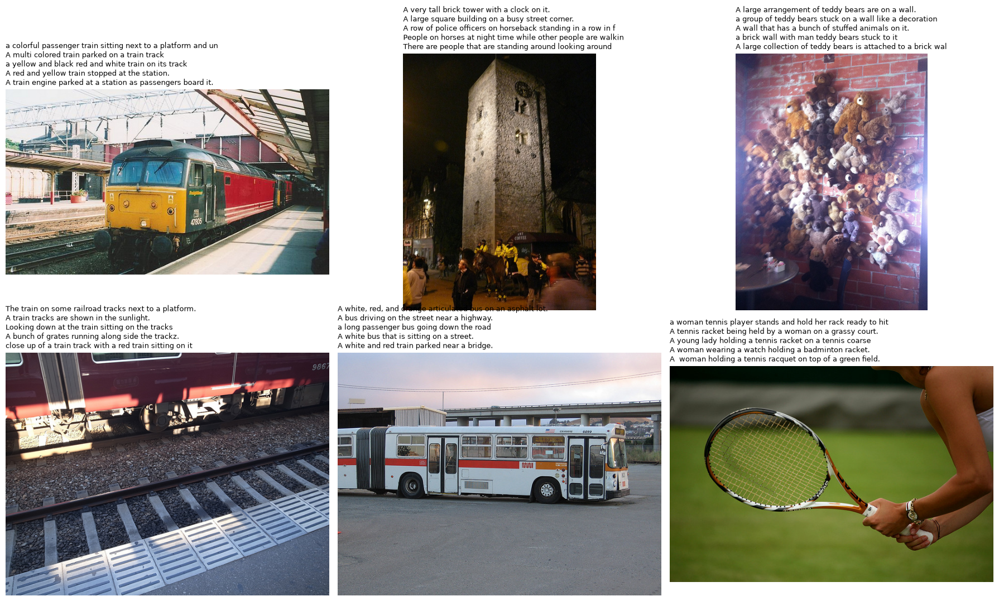

[Block 2d] OK


In [6]:
print("[Block 2d] Visual inspection : starting...")

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, (_, row) in zip(axes.flat, train_df.sample(6, random_state=SEED).iterrows()):
    ax.imshow(iio.imread(row["path"]), cmap="gray")
    ax.axis("off")
    ax.set_title("\n".join(c.strip()[:60] for c in row["captions"][:5]), fontsize=9, loc="left")
plt.tight_layout()
plt.show()

print("[Block 2d] OK")

## 3. Image Preprocessing: the CNN (InceptionV3)

The CNN is already trained on ImageNet (1.2 million photos). We remove its last layer (the 1,000 classes) and keep
the layer before: a vector that describes the content of the image. The CNN is **frozen** (not trained).

The tutorial uses VGG16. We use **InceptionV3**, which is better on every point that matters here:

| | VGG16 (tutorial) | InceptionV3 (ours) |
|---|---|---|
| ImageNet accuracy (top-1) | 71.3 % | 77.9 % |
| weights | 138 M | 24 M |
| input size | 224 x 224 | 299 x 299 |
| layer used | `fc2` | `avg_pool` (global average pooling) |
| vector per image | 4,096 numbers | 2,048 numbers |

```txt
image -> resize 299 x 299 -> preprocess_input (pixels in [-1, 1]) -> InceptionV3 -> avg_pool (2048)
```

`ENCODER = "VGG16"` (section 1) gives back the tutorial's setup, to compare the two. Each CNN has its own cache
files and its own model file, so both can be kept.

The CNN is slow but its output never changes, so we run it **once** per image and save the vectors to disk
(`data/coco_features/*.npy`). Training then reads small vectors instead of images: about 0.1 GB instead of
30 GB of RAM for 30,000 images.

In [7]:
print("[Block 3] CNN features : starting...")

AUTOTUNE = tf.data.AUTOTUNE

def build_encoder(name):
    # Pretrained CNN without its last layer, and its own preprocessing function
    if name == "InceptionV3":
        cnn = InceptionV3(include_top=True, weights="imagenet")
        return keras.Model(cnn.input, cnn.get_layer("avg_pool").output, name="InceptionV3_avg_pool"), inception_v3.preprocess_input
    if name == "VGG16":
        cnn = VGG16(include_top=True, weights="imagenet")
        return keras.Model(cnn.input, cnn.get_layer("fc2").output, name="VGG16_fc2"), vgg16.preprocess_input
    raise ValueError(f"unknown encoder {name}")

encoder, preprocess_input = build_encoder(ENCODER)
IMG_SIZE = tuple(encoder.input_shape[1:3])   # 299 x 299 for InceptionV3, 224 x 224 for VGG16
FEATURE_SIZE = encoder.output_shape[-1]       # 2048 for InceptionV3, 4096 for VGG16
print(f"  encoder {encoder.name}: {encoder.count_params():,} weights (frozen), input {IMG_SIZE}, "
      f"output: {FEATURE_SIZE} numbers per image")

def load_for_encoder(path):
    # Read the image in RGB, resize to the CNN input size, apply the CNN preprocessing
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    return preprocess_input(img)

def image_features(table, name):
    # CNN vectors of the images, computed once then read from disk (one file per CNN)
    cache, order = FEATURES / f"{encoder.name}_{name}.npy", FEATURES / f"{encoder.name}_{name}.csv"
    paths = table["path"].tolist()
    if cache.exists() and order.exists() and pd.read_csv(order)["path"].tolist() == paths:
        print(f"  {name}: read from {cache}")
        return np.load(cache)
    start = time.time()
    ds = tf.data.Dataset.from_tensor_slices(paths).map(load_for_encoder, num_parallel_calls=AUTOTUNE)
    feats = encoder.predict(ds.batch(FEATURE_BATCH).prefetch(AUTOTUNE), verbose=0).astype("float16")
    np.save(cache, feats)
    pd.DataFrame({"path": paths}).to_csv(order, index=False)   # to check the order next time
    print(f"  {name}: {len(paths)} images in {time.time() - start:.0f} s "
          f"({(time.time() - start) / len(paths) * 1000:.1f} ms per image)")
    return feats

feats_train = image_features(train_df, "train")
feats_val = image_features(val_df, "val")
feats_test = image_features(test_df, "test")

print(f"  train {feats_train.shape}, val {feats_val.shape}, test {feats_test.shape}, dtype {feats_train.dtype}")
print(f"  memory of the train vectors: {feats_train.nbytes / 1e9:.2f} GB "
      f"(the same images in float32: {len(train_df) * IMG_SIZE[0] * IMG_SIZE[1] * 3 * 4 / 1e9:.1f} GB)")

print("[Block 3] OK")

[Block 3] CNN features : starting...


W0000 00:00:1792413154.930724   21374 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1792413154.931263   21374 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13508 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4090 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


96112376/96112376 ━━━━━━━━━━━━━━━━━━━━ 9s 0us/step
  encoder InceptionV3_avg_pool: 21,802,784 weights (frozen), input (299, 299), output: 2048 numbers per image


I0000 00:00:1792413170.072735   22030 service.cc:153] XLA service 0x75a33c06e4a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792413170.072781   22030 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4090 Laptop GPU, Compute Capability 8.9 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792413170.143818   22030 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792413171.227774   22030 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1792413184.786867   22030 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


  train: 27000 images in 53 s (2.0 ms per image)


W0000 00:00:1792413220.782624   21374 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 134217728 bytes after encountering the first element of size 134217728 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


  val: 3000 images in 3 s (0.9 ms per image)


W0000 00:00:1792413223.573229   21374 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 134217728 bytes after encountering the first element of size 134217728 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


  test: 5000 images in 13 s (2.5 ms per image)
  train (27000, 2048), val (3000, 2048), test (5000, 2048), dtype float16
  memory of the train vectors: 0.11 GB (the same images in float32: 29.0 GB)
[Block 3] OK


## 4. Text Preprocessing

4 steps to turn a caption into numbers:
1. **cleaning**: lower case, only letters, digits and spaces;
2. **markers**: `ssss` at the start, `eeee` at the end (the network writes `eeee` to stop);
3. **vocabulary**: each of the `NUM_WORDS` most frequent words gets a number (0 = padding, 1 = unknown word);
4. **length**: captions longer than the 99th percentile are removed, the others are padded with zeros.

[Block 4a] Cleaning and vocabulary : starting...
  14,697 different words in the training captions, vocabulary: 10,000 -> 99.67% of the words written are known
  caption length: median 10 words, 99th percentile 19 -> SEQ_LEN = 21
  ssss = 3, eeee = 4, first words: ['', '[UNK]', 'a', 'ssss', 'eeee', 'on', 'of', 'the', 'in', 'with', 'and', 'is']


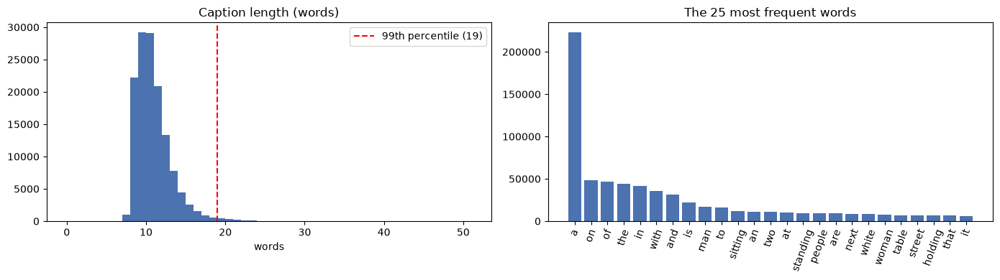

[Block 4a] OK


In [8]:
print("[Block 4a] Cleaning and vocabulary : starting...")

def clean_caption(text):
    # Lower case, only letters / digits / spaces (also used for BLEU)
    return " ".join(re.sub(r"[^a-z0-9 ]", " ", text.lower()).split())

def mark(text):
    return f"{MARK_START} {text} {MARK_END}"

for table in (train_df, val_df, test_df):
    table["clean"] = table["captions"].apply(lambda caps: [clean_caption(c) for c in caps])

train_caps = train_df.explode("clean")   # one row per caption
lengths = train_caps["clean"].str.split().str.len()
MAX_WORDS = int(np.percentile(lengths, 99))   # max caption length
SEQ_LEN = MAX_WORDS + 2                       # + ssss + eeee

word_counts = Counter(w for c in train_caps["clean"] for w in c.split())
vectorizer = layers.TextVectorization(max_tokens=NUM_WORDS, standardize=None, split="whitespace",
                                      output_mode="int", output_sequence_length=SEQ_LEN)
vectorizer.adapt(train_caps["clean"].map(mark).to_numpy())
VOCAB = [str(w) for w in vectorizer.get_vocabulary()]   # VOCAB[number] = word
WORD_INDEX = {w: i for i, w in enumerate(VOCAB)}
TOKEN_START, TOKEN_END = WORD_INDEX[MARK_START], WORD_INDEX[MARK_END]
VOCAB_SIZE = len(VOCAB)                  # <= NUM_WORDS

covered = sum(n for w, n in word_counts.items() if w in WORD_INDEX) / sum(word_counts.values())
print(f"  {len(word_counts):,} different words in the training captions, vocabulary: {len(VOCAB):,} "
      f"-> {covered:.2%} of the words written are known")
print(f"  caption length: median {int(lengths.median())} words, 99th percentile {MAX_WORDS} -> SEQ_LEN = {SEQ_LEN}")
print(f"  ssss = {TOKEN_START}, eeee = {TOKEN_END}, first words: {VOCAB[:12]}")

MODEL_NAME = f"Hvass_GRU_{ENCODER}"   # one captioning model per CNN

# Saved for 04_pipeline.ipynb: same vocabulary and same CNN needed in production
with open(RESULTS / f"caption_{MODEL_NAME}_vocab.json", "w") as f:
    json.dump({"vocab": VOCAB, "max_words": MAX_WORDS, "mark_start": MARK_START, "mark_end": MARK_END,
               "encoder": ENCODER, "model": f"caption_{MODEL_NAME}.keras"}, f)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.hist(lengths, bins=range(0, lengths.max() + 2), color="#4c72b0")
ax1.axvline(MAX_WORDS, color="red", ls="--", label=f"99th percentile ({MAX_WORDS})")
ax1.set_title("Caption length (words)"); ax1.set_xlabel("words"); ax1.legend()
top = pd.Series(dict(word_counts.most_common(25)))
ax2.bar(top.index, top.values, color="#4c72b0"); ax2.tick_params(axis="x", rotation=70)
ax2.set_title("The 25 most frequent words")
plt.tight_layout()
plt.show()

print("[Block 4a] OK")

### 4.1 Training pairs

The network learns to **predict the next word**. For `ssss a dog runs eeee`:

| input | word to predict |
|---|---|
| `ssss` | `a` |
| `ssss a` | `dog` |
| `ssss a dog` | `runs` |
| `ssss a dog runs` | `eeee` |

So: input = caption without its last word, target = caption shifted by one word. One example = (CNN vector,
one caption). Every caption is used once per epoch.

In [9]:
print("[Block 4b] Training pairs : starting...")

def caption_table(table):
    # One row per (image, caption): image index + caption as numbers
    rows = table.reset_index(drop=True).explode("clean").reset_index(names="img_idx")
    rows = rows[rows["clean"].str.split().str.len() <= MAX_WORDS]   # remove too long captions
    tokens = vectorizer(rows["clean"].map(mark).to_numpy()).numpy().astype("int32")
    return rows["img_idx"].to_numpy("int32"), tokens

def make_dataset(features, table, shuffle=False):
    img_idx, tokens = caption_table(table)
    feats = tf.constant(features)
    ds = tf.data.Dataset.from_tensor_slices((img_idx, tokens))
    if shuffle:
        ds = ds.shuffle(len(img_idx), seed=SEED, reshuffle_each_iteration=True)

    def to_pairs(i, t):
        t = t[:, :tf.reduce_max(tf.math.count_nonzero(t, axis=1, dtype=tf.int32))]   # remove useless padding
        x = {"transfer_values_input": tf.cast(tf.gather(feats, i), tf.float32),
             "decoder_input": t[:, :-1]}     # ssss a dog runs
        return x, t[:, 1:]                   # a dog runs eeee
    return ds.batch(BATCH).map(to_pairs, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE), len(img_idx)

train_ds, n_train_caps = make_dataset(feats_train, train_df, shuffle=True)
val_ds, n_val_caps = make_dataset(feats_val, val_df)
print(f"  train: {n_train_caps} captions ({n_train_caps // BATCH + 1} batches of {BATCH}), val: {n_val_caps} captions")

x, y = next(iter(train_ds))
print("  transfer values:", x["transfer_values_input"].shape, "| decoder input:", x["decoder_input"].shape,
      "| target:", y.shape)
print("  example input :", " ".join(VOCAB[t] for t in x["decoder_input"][0].numpy() if t))
print("  example target:", " ".join(VOCAB[t] for t in y[0].numpy() if t))

print("[Block 4b] OK")

[Block 4b] Training pairs : starting...


E0000 00:00:1792413238.426374   21374 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


  train: 133997 captions (349 batches of 384), val: 14888 captions
  transfer values: (384, 2048) | decoder input: (384, 20) | target: (384, 20)
  example input : ssss two cows on a city street amongst cars and a motor bike eeee
  example target: two cows on a city street amongst cars and a motor bike eeee
[Block 4b] OK


## 5. The Captioning Network (Hvass #22)

```txt
 image ──> InceptionV3 (2048) ──> Dense 512 tanh ──┐ initial state
                                                 ▼
 words ──> Embedding (128) ──> GRU 512 ──> GRU 512 ──> GRU 512 ──> Dense softmax (1 probability per word)
```

- **Image -> RNN**: a Dense layer reduces the 2,048 numbers to 512, the size of the GRU memory. This vector is
  the **initial state** of the 3 GRU layers: the network "knows" the image before reading any word.
- **Embedding**: each word number becomes a vector of 128 numbers, learned during training.
- **GRU**: reads the words one by one and keeps a memory (512 numbers). Its gates choose what to keep or forget,
  which works better than a simple RNN on long sentences.
- **Output**: softmax over the vocabulary = probability of each possible next word.

**Loss**: sparse categorical cross-entropy (a classification over the vocabulary, for each word), padding ignored.
**Optimizer**: RMSprop, learning rate 1e-3 (as in the tutorial), well suited to RNNs.

[Block 5] Captioning network : definition...


Model: "Hvass_GRU_InceptionV3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ decoder_input       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transfer_values_in… │ (None, 2048)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding   │ (None, None, 128) │  1,280,000 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_transfer_m… │ (None, 512)       │  1,049,088 │ transfer_values_… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_gru1 (GRU)  │ (None, None, 512) │    986,112 │ decoder_embeddin… │
│                     │                   │            │ decoder_transfer… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_gru2 (GRU)  │ (None, None, 512) │  1,575,936 │ decoder_gru1[0][… │
│                     │                   │            │ decoder_transfer… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_gru3 (GRU)  │ (None, None, 512) │  1,575,936 │ decoder_gru2[0][… │
│                     │                   │            │ decoder_transfer… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_output      │ (None, None,      │  5,130,000 │ decoder_gru3[0][… │
│ (Dense)             │ 10000)            │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 11,597,072 (44.24 MB)

 Trainable params: 11,597,072 (44.24 MB)

 Non-trainable params: 0 (0.00 B)

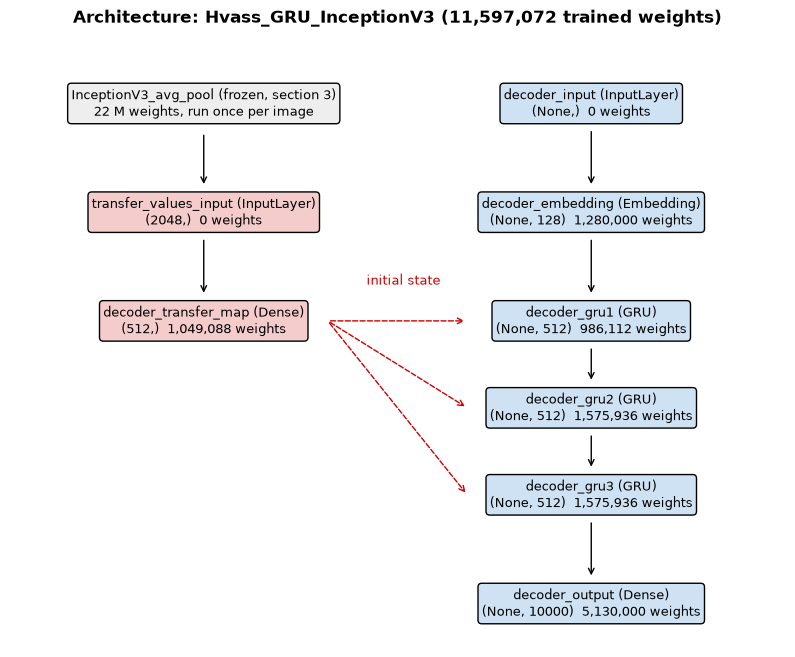

[Block 5] OK


In [10]:
print("[Block 5] Captioning network : definition...")

def build_hvass_decoder(name=None):
    name = name or MODEL_NAME
    # Same as the tutorial (connect_decoder), in Keras 3, with padding masked
    transfer_values_input = keras.Input(shape=(FEATURE_SIZE,), name="transfer_values_input")
    decoder_input = keras.Input(shape=(None,), dtype="int32", name="decoder_input")

    # Image vector -> initial state of the GRU layers
    initial_state = layers.Dense(STATE_SIZE, activation="tanh", name="decoder_transfer_map")(transfer_values_input)

    net = layers.Embedding(VOCAB_SIZE, EMBEDDING_SIZE, mask_zero=True, name="decoder_embedding")(decoder_input)
    for i in (1, 2, 3):
        net = layers.GRU(STATE_SIZE, return_sequences=True, name=f"decoder_gru{i}")(net, initial_state=initial_state)
    decoder_output = layers.Dense(VOCAB_SIZE, activation="softmax", name="decoder_output")(net)
    return keras.Model({"transfer_values_input": transfer_values_input, "decoder_input": decoder_input},
                       decoder_output, name=name)

def draw_captioning_architecture(model):
    # Diagram of the 2 branches (image and text)
    boxes = {   # layer name: (x, y)
        "transfer_values_input": (2.5, 6), "decoder_transfer_map": (2.5, 4.5),
        "decoder_input": (7.5, 7.5), "decoder_embedding": (7.5, 6),
        "decoder_gru1": (7.5, 4.5), "decoder_gru2": (7.5, 3.3), "decoder_gru3": (7.5, 2.1),
        "decoder_output": (7.5, 0.6)}
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.set_xlim(0, 10); ax.set_ylim(0, 8.5); ax.axis("off")
    ax.text(2.5, 7.5, f"{encoder.name} (frozen, section 3)\n{encoder.count_params() / 1e6:.0f} M weights, run once per image", ha="center",
            va="center", fontsize=9, bbox=dict(boxstyle="round", fc="#eeeeee"))
    ax.annotate("", xy=(2.5, 6.35), xytext=(2.5, 7.1), arrowprops=dict(arrowstyle="->"))
    for layer in model.layers:
        x, y = boxes[layer.name]
        shape = str(tuple(layer.output.shape[1:]))
        ax.text(x, y, f"{layer.name} ({type(layer).__name__})\n{shape}  {layer.count_params():,} weights",
                ha="center", va="center", fontsize=9,
                bbox=dict(boxstyle="round", fc="#f4cccc" if x < 5 else "#cfe2f3"))
    for a, b in [("transfer_values_input", "decoder_transfer_map"), ("decoder_input", "decoder_embedding"),
                 ("decoder_embedding", "decoder_gru1"), ("decoder_gru1", "decoder_gru2"),
                 ("decoder_gru2", "decoder_gru3"), ("decoder_gru3", "decoder_output")]:
        (xa, ya), (xb, yb) = boxes[a], boxes[b]
        ax.annotate("", xy=(xb, yb + 0.35), xytext=(xa, ya - 0.35), arrowprops=dict(arrowstyle="->"))
    for g in ("decoder_gru1", "decoder_gru2", "decoder_gru3"):   # initial state arrows
        ax.annotate("", xy=(boxes[g][0] - 1.6, boxes[g][1]), xytext=(4.1, 4.5),
                    arrowprops=dict(arrowstyle="->", color="#cc0000", ls="--"))
    ax.text(4.6, 5.0, "initial state", color="#cc0000", fontsize=9)
    ax.set_title(f"Architecture: {model.name} ({model.count_params():,} trained weights)", fontweight="bold")
    plt.show()

decoder = build_hvass_decoder()
decoder.summary()
draw_captioning_architecture(decoder)

print("[Block 5] OK")

### 5.1 Writing a caption

During training the network gets the right previous words. To write a new caption, it uses its own words:
start with `ssss`, predict a word, add it to the input, and repeat until `eeee`.

Two ways to choose the word:
- **greedy**: always the most probable word (fast);
- **beam search**: keep the 3 best sentences at each step, return the best one at the end (usually better).

In [11]:
print("[Block 5.1] Caption generation : definition...")

def tokens_to_text(tokens):
    # Numbers -> sentence (stops at eeee)
    words = []
    for t in tokens[1:]:
        if t == TOKEN_END or t == 0:
            break
        words.append(VOCAB[t])
    return " ".join(words)

def next_word_probs(model, feats, tokens):
    # Probabilities of the next word (last position)
    out = model({"transfer_values_input": feats, "decoder_input": tokens}, training=False)
    return np.array(out[:, -1], dtype="float64")

def greedy_captions(model, features, max_words=None, batch=500):
    max_words = max_words or MAX_WORDS
    captions = []
    for s in range(0, len(features), batch):
        feats = np.asarray(features[s:s + batch], dtype="float32")
        tokens = np.zeros((len(feats), max_words + 2), dtype="int32")
        tokens[:, 0] = TOKEN_START
        done = np.zeros(len(feats), dtype=bool)
        for t in range(max_words + 1):
            probs = next_word_probs(model, feats, tokens[:, :t + 1])
            probs[:, :2] = 0                       # never padding or [UNK]
            word = probs.argmax(axis=1)
            word[done] = 0                          # finished captions get padding
            tokens[:, t + 1] = word
            done |= word == TOKEN_END
            if done.all():
                break
        captions += [tokens_to_text(row) for row in tokens]
    return captions

def beam_captions(model, features, beam=BEAM, max_words=None, alpha=0.7, batch=200):
    max_words, V = max_words or MAX_WORDS, VOCAB_SIZE
    captions = []
    for s in range(0, len(features), batch):
        feats = np.repeat(np.asarray(features[s:s + batch], dtype="float32"), beam, axis=0)   # 1 copy per beam
        B = len(feats) // beam
        tokens = np.zeros((B * beam, max_words + 2), dtype="int32")
        tokens[:, 0] = TOKEN_START
        score = np.full((B, beam), -1e9); score[:, 0] = 0.0   # log-probability of each sentence
        length = np.zeros((B, beam))
        done = np.zeros((B, beam), dtype=bool)
        for t in range(max_words + 1):
            logp = np.log(np.maximum(next_word_probs(model, feats, tokens[:, :t + 1]), 1e-12)).reshape(B, beam, V)
            logp[..., :2] = -1e9                                  # never padding or [UNK]
            cand = np.where(done[..., None], -1e9, score[..., None] + logp)
            cand[..., 0] = np.where(done, score, -1e9)            # finished sentences stay unchanged
            flat = cand.reshape(B, beam * V)
            best = np.argsort(-flat, axis=1)[:, :beam]            # keep the best candidates
            src, word = best // V, best % V
            tokens = tokens[(np.arange(B)[:, None] * beam + src).ravel()]
            tokens[:, t + 1] = word.ravel()
            score = np.take_along_axis(flat, best, axis=1)
            was_done = np.take_along_axis(done, src, axis=1)
            length = np.take_along_axis(length, src, axis=1) + ~was_done
            done = was_done | (word == TOKEN_END)
            if done.all():
                break
        pick = (score / np.maximum(length, 1) ** alpha).argmax(axis=1)   # normalized by length
        captions += [tokens_to_text(tokens[b * beam + pick[b]]) for b in range(B)]
    return captions

def bleu_scores(references, hypotheses):
    # Corpus BLEU-1 to 4 (0 = nothing in common with the human captions, 1 = identical)
    refs = [[r.split() for r in rs] for rs in references]
    hyps = [h.split() for h in hypotheses]
    return {f"BLEU-{n}": corpus_bleu(refs, hyps, weights=tuple([1 / n] * n)) for n in (1, 2, 3, 4)}

print("  before training:", greedy_captions(decoder, feats_val[:2]))   # random words

print("[Block 5.1] OK")

[Block 5.1] Caption generation : definition...
  before training: ['claus reveals suck unenthused unenthused piece piece piece glides glides glides glides word stools cruises elphant demonic demonic condition condition', 'crouch palms palms interstate interstate adorn bibs bibs bibs walks boarder boarder boarder conveyor conveyor remains remains birds birds tidy']
[Block 5.1] OK


## 6. Training

Same callbacks as in deliverables 1 and 2:
- **ModelCheckpoint**: saves the best epoch (lowest validation loss);
- **EarlyStopping**: stops after 5 epochs without progress and restores the best weights;
- **ReduceLROnPlateau**: halves the learning rate after 2 epochs without progress;
- **BleuCallback**: BLEU-4 on 500 validation images after each epoch (quality of the sentences written alone).

`RETRAIN = False` reloads the saved model instead of training it again. The model file is
`results/caption_Hvass_GRU_<ENCODER>.keras`.

In [12]:
print("[Block 6] Training function : definition...")

# True = train again, False = reload the saved model
RETRAIN = {"Hvass_GRU_InceptionV3": True, "Hvass_GRU_VGG16": False}

models = {}   # the trained (or reloaded) models

class BleuCallback(keras.callbacks.Callback):
    # BLEU-4 on validation images at each epoch (written in the CSV log)
    def __init__(self, features, table, n=500):
        super().__init__()
        self.features, self.refs = features[:n], table["clean"].iloc[:n].tolist()
    def on_epoch_end(self, epoch, logs=None):
        hyps = greedy_captions(self.model, self.features)
        logs["val_bleu4"] = bleu_scores(self.refs, hyps)["BLEU-4"]
        print(f"  val BLEU-4 = {logs['val_bleu4']:.4f} | e.g. '{hyps[0]}'")

def train(model, epochs=EPOCHS):
    ckpt = RESULTS / f"caption_{model.name}.keras"
    if not RETRAIN.get(model.name, True) and ckpt.exists():
        models[model.name] = keras.models.load_model(ckpt)
        print(f"{model.name}: reloaded from {ckpt} (RETRAIN = False)")
        return
    model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=LR),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])   # share of next words predicted right
    callbacks = [
        BleuCallback(feats_val, val_df),   # first, so that CSVLogger sees val_bleu4
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(str(ckpt), monitor="val_loss", save_best_only=True),
        keras.callbacks.CSVLogger(str(LOGS / f"caption_{model.name}_history.csv")),
        keras.callbacks.TensorBoard(log_dir=str(LOGS / f"caption_{model.name}")),
    ]
    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=2)
    print(f"{model.name}: trained in {(time.time() - start) / 60:.1f} min, {len(history.history['loss'])} epochs")
    models[model.name] = model

def plot_history(name):
    h = pd.read_csv(LOGS / f"caption_{name}_history.csv")
    best = h["val_loss"].idxmin()
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    for ax, (key, title) in zip(axes, [("loss", "loss (cross-entropy)"), ("accuracy", "next-word accuracy")]):
        ax.plot(h["epoch"] + 1, h[key], label="train"); ax.plot(h["epoch"] + 1, h[f"val_{key}"], label="validation")
        ax.axvline(best + 1, color="grey", ls=":", label="best epoch (kept)")
        ax.set_title(f"{name} - {title}"); ax.set_xlabel("epoch"); ax.legend()
    axes[2].plot(h["epoch"] + 1, h["val_bleu4"], color="green", marker="o")
    axes[2].axvline(best + 1, color="grey", ls=":")
    axes[2].set_title(f"{name} - BLEU-4 (500 validation images, greedy)"); axes[2].set_xlabel("epoch")
    plt.tight_layout()
    plt.show()
    print(f"  best epoch {best + 1}: train loss {h.loss[best]:.3f}, val loss {h.val_loss[best]:.3f}, "
          f"gap {h.val_loss[best] - h.loss[best]:+.3f} | val accuracy {h.val_accuracy[best]:.3f} | "
          f"val BLEU-4 {h.val_bleu4[best]:.4f}")

print("[Block 6] OK")

[Block 6] Training function : definition...
[Block 6] OK


### 6.1 Training the captioning model

In [13]:
print(f"[Block 6.1] Training {MODEL_NAME} : starting...")

train(build_hvass_decoder())

print("[Block 6.1] OK")

[Block 6.1] Training Hvass_GRU_InceptionV3 : starting...
Epoch 1/50


/usr/local/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  val BLEU-4 = 0.0460 | e.g. 'a zebras of a in a in a'
349/349 - 34s - 98ms/step - accuracy: 0.2387 - loss: 4.6439 - val_accuracy: 0.3152 - val_loss: 3.9913 - val_bleu4: 0.0460 - learning_rate: 0.0010
Epoch 2/50
  val BLEU-4 = 0.1602 | e.g. 'a zebra standing in a grass in a field'
349/349 - 31s - 88ms/step - accuracy: 0.3777 - loss: 3.5127 - val_accuracy: 0.4039 - val_loss: 3.2303 - val_bleu4: 0.1602 - learning_rate: 0.0010
Epoch 3/50
  val BLEU-4 = 0.1976 | e.g. 'a zebra standing in a field with a zebra'
349/349 - 31s - 88ms/step - accuracy: 0.4187 - loss: 3.1243 - val_accuracy: 0.4300 - val_loss: 3.0154 - val_bleu4: 0.1976 - learning_rate: 0.0010
Epoch 4/50
  val BLEU-4 = 0.2000 | e.g. 'a zebra standing in a field with a zebra in the background'
349/349 - 30s - 87ms/step - accuracy: 0.4427 - loss: 2.9218 - val_accuracy: 0.4457 - val_loss: 2.8788 - val_bleu4: 0.2000 - learning_rate: 0.0010
Epoch 5/50
  val BLEU-4 = 0.2174 | e.g. 'a zebra standing in a field with a zebra in the backgro

### 6.2 Training Curves

[Block 6.2] Training curves : starting...


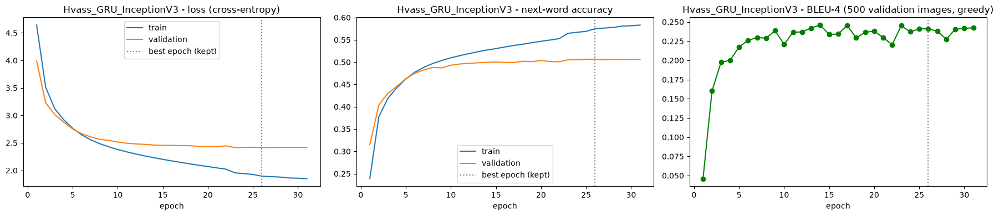

  best epoch 26: train loss 1.895, val loss 2.414, gap +0.520 | val accuracy 0.507 | val BLEU-4 0.2410
[Block 6.2] OK


In [14]:
print("[Block 6.2] Training curves : starting...")

plot_history(MODEL_NAME)

print("[Block 6.2] OK")

## 7. Evaluation on the Test Set (COCO val2017)

**BLEU** compares the generated caption with the 5 human captions: it counts the groups of 1 to 4 words they have
in common (score from 0 to 1). BLEU-4 is the strictest. For comparison, *Show and Tell* (Vinyals et al. 2015,
an architecture close to ours, trained on all of COCO) gets BLEU-4 ≈ 0.28.

Two simple baselines to compare with:
- **constant caption**: the most frequent training caption for every image;
- **nearest neighbour**: the caption of the most similar training image (cosine distance on the CNN vectors).

In [15]:
print("[Block 7] Evaluation : starting...")

model = models[MODEL_NAME]
test_refs = test_df["clean"].tolist()
results, generated = {}, {}

# Baseline 1: always the same caption
constant = train_caps["clean"].value_counts().index[0]
generated["Constant caption"] = [constant] * len(test_df)

# Baseline 2: caption of the most similar training image (cosine distance on the CNN vectors)
def normalize(f):
    f = np.asarray(f, dtype="float32")
    return f / np.linalg.norm(f, axis=1, keepdims=True)
train_unit = normalize(feats_train)
nearest = np.concatenate([(normalize(feats_test[s:s + 1000]) @ train_unit.T).argmax(axis=1)
                          for s in range(0, len(feats_test), 1000)])
generated[f"Nearest neighbour ({ENCODER})"] = [train_df["clean"].iloc[i][0] for i in nearest]

# Our network, greedy and beam search
GREEDY, BEAM_LABEL = f"{MODEL_NAME} greedy", f"{MODEL_NAME} beam {BEAM}"
for label, fn in ((GREEDY, greedy_captions), (BEAM_LABEL, beam_captions)):
    start = time.time()
    generated[label] = fn(model, feats_test)
    print(f"  {label}: {len(test_df)} captions in {time.time() - start:.0f} s")

for label, hyps in generated.items():
    results[label] = bleu_scores(test_refs, hyps)
    results[label]["distinct captions"] = len(set(hyps)) / len(hyps)   # 1 = all different
    results[label]["words used"] = len({w for h in hyps for w in h.split()})
    results[label]["mean length"] = np.mean([len(h.split()) for h in hyps])

# One table for all the runs: rows of a previous run with another CNN are kept, to compare the CNNs
results = pd.DataFrame(results).T
results_file = RESULTS / "deliverable3_results.csv"
if results_file.exists():
    previous = pd.read_csv(results_file, index_col=0)
    results = pd.concat([previous.drop(index=results.index, errors="ignore"), results])
display(results.round(4))
results.to_csv(results_file)

print("[Block 7] OK")

[Block 7] Evaluation : starting...
  Hvass_GRU_InceptionV3 greedy: 5000 captions in 9 s
  Hvass_GRU_InceptionV3 beam 3: 5000 captions in 116 s


,BLEU-1,BLEU-2,BLEU-3,BLEU-4,distinct captions,words used,mean length
Constant caption,0.4386,0.2161,0.1185,0.0750,0.0002,8.0,10.0000
Nearest neighbour (InceptionV3),0.4999,0.3038,0.1848,0.1148,0.8186,2980.0,10.4474
Hvass_GRU_InceptionV3 greedy,0.6629,0.4787,0.3347,0.2337,0.7690,787.0,9.6888
Hvass_GRU_InceptionV3 beam 3,0.6634,0.4822,0.3466,0.2518,0.6770,717.0,9.7310


[Block 7] OK


### 7.1 Examples on Test Images

8 random test images: caption of the network (greedy and beam) and 2 human captions.

[Block 7.1] Examples : starting...


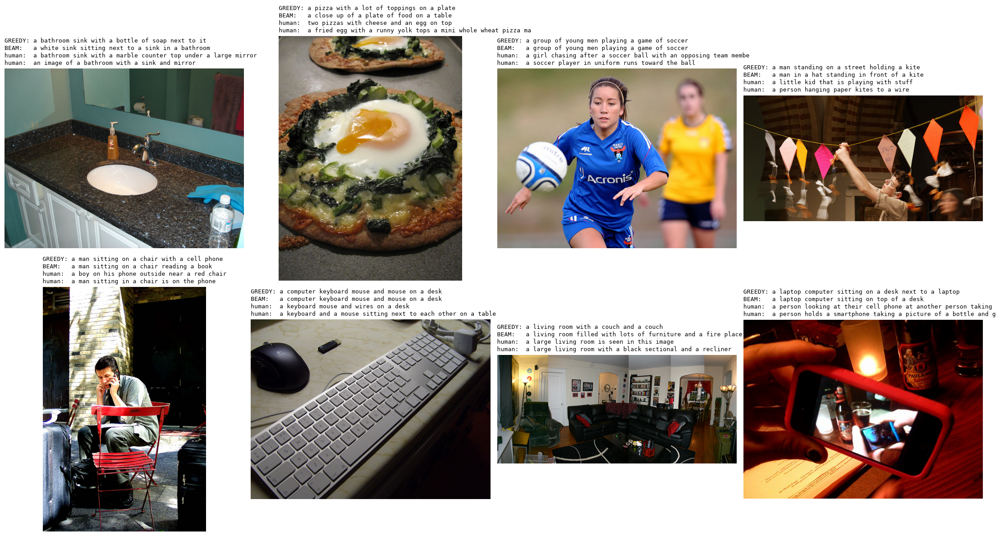

[Block 7.1] OK


In [16]:
print("[Block 7.1] Examples : starting...")

def show_examples(indices, extra=None):
    fig, axes = plt.subplots(2, 4, figsize=(22, 12))
    for ax, i in zip(axes.flat, indices):
        row = test_df.iloc[i]
        ax.imshow(iio.imread(row["path"]), cmap="gray")
        ax.axis("off")
        lines = [f"GREEDY: {generated[GREEDY][i]}", f"BEAM:   {generated[BEAM_LABEL][i]}",
                 f"human:  {row['clean'][0]}", f"human:  {row['clean'][1]}"]
        if extra is not None:
            lines.insert(0, extra[i])
        ax.set_title("\n".join(l[:70] for l in lines), fontsize=9, loc="left", family="monospace")
    plt.tight_layout()
    plt.show()

show_examples(np.random.default_rng().choice(len(test_df), size=8, replace=False))   # new images at each run

print("[Block 7.1] OK")

### 7.2 Best and Worst Captions

BLEU-4 per image (with smoothing): the 4 best and the 4 worst test images.

[Block 7.2] Best and worst : starting...
  first row: the 4 best, second row: the 4 worst


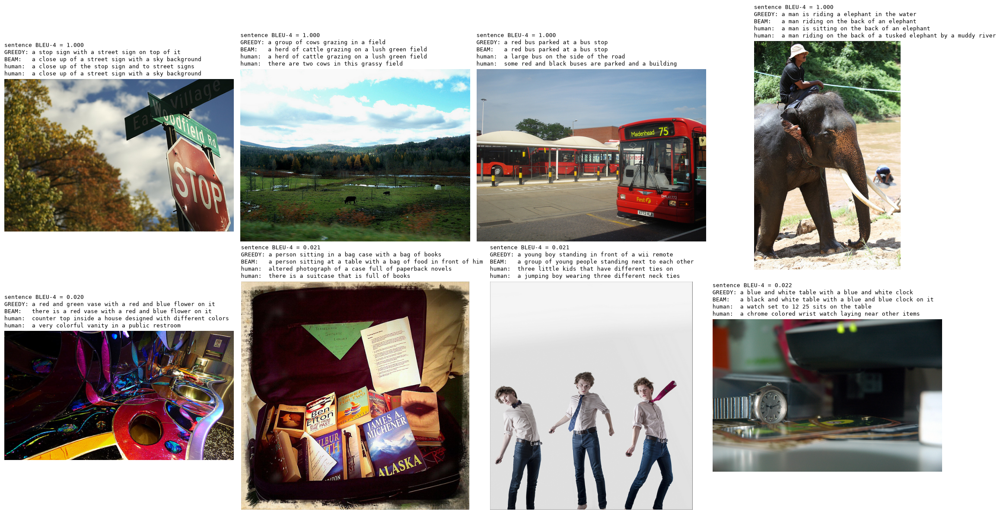

,times written
a man riding a wave on top of a surfboard,56
a bathroom with a toilet and a sink,41
a man holding a tennis racquet on a tennis court,41
a man riding skis down a snow covered slope,30
a group of people standing next to each other,21
a red stop sign sitting on the side of a road,21
a woman sitting at a table with a plate of food,20
a close up of a plate of food on a table,18
a laptop computer sitting on top of a wooden desk,18
a group of people riding skis down a snow covered slope,18


[Block 7.2] OK


In [17]:
print("[Block 7.2] Best and worst : starting...")

smooth = SmoothingFunction().method1
sentence_scores = np.array([sentence_bleu([r.split() for r in refs], hyp.split(), smoothing_function=smooth)
                            for refs, hyp in zip(test_refs, generated[BEAM_LABEL])])
order = np.argsort(sentence_scores)
labels = {i: f"sentence BLEU-4 = {sentence_scores[i]:.3f}" for i in range(len(test_df))}
print("  first row: the 4 best, second row: the 4 worst"); show_examples(order[::-1][:4].tolist() + order[:4].tolist(), extra=labels)

# Most frequent generated captions (generic sentences)
display(pd.Series(generated[BEAM_LABEL]).value_counts().head(10).rename("times written").to_frame())

print("[Block 7.2] OK")

## 8. Robustness to Noise (link with Deliverable 2)

Does noise change the captions, and does the denoiser of deliverable 2 (`denoise_UNet_deep.keras`) help? On
500 test images, we compare the BLEU-4 of 3 versions of each image: **clean**, **noisy**, **denoised**.
The noises are those of deliverable 2 (Gaussian, salt and pepper, JPEG).

[Block 8] Robustness to noise : starting...


W0000 00:00:1792414383.802313   21374 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 7.22GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


,BLEU-4 clean,BLEU-4 noisy,BLEU-4 denoised,"same caption as clean, noisy","same caption as clean, denoised"
gaussian 0.15,0.2523,0.2109,0.2101,0.062,0.092
salt & pepper 6 %,0.2523,0.1578,0.2303,0.042,0.296
JPEG quality 10,0.2523,0.1899,0.1914,0.088,0.096


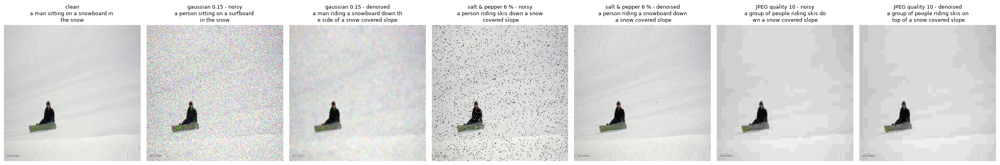

[Block 8] OK


In [18]:
print("[Block 8] Robustness to noise : starting...")

denoiser = keras.models.load_model(RESULTS / "denoise_UNet_deep.keras", compile=False)   # best model of D2
DENOISE_SIZE = tuple(denoiser.input_shape[1:3])   # 256 x 256
N_ROBUST = 500
rng = np.random.default_rng(SEED)

def load_01(path):
    # Same loading as deliverable 2: RGB, 256 x 256, pixels in [0, 1]
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.clip_by_value(tf.round(tf.image.resize(img, DENOISE_SIZE, antialias=True)), 0, 255)
    return img.numpy() / 255.0

# Noises of deliverable 2, at a fixed strong level
def gaussian(x):    return x + rng.normal(0, 0.15, x.shape)
def salt_pepper(x):
    u = rng.random(x.shape[:-1])[..., None]
    return np.where(u < 0.03, 1.0, np.where(u > 0.97, 0.0, x))
def jpeg(x):        return tf.image.adjust_jpeg_quality(x, 10).numpy()
NOISES = {"gaussian 0.15": gaussian, "salt & pepper 6 %": salt_pepper, "JPEG quality 10": jpeg}

def features_01(images):
    # Images in [0, 1] -> CNN vectors (same preprocessing as section 3)
    x = tf.image.resize(np.asarray(images, dtype="float32") * 255.0, IMG_SIZE)
    return encoder.predict(preprocess_input(x), batch_size=FEATURE_BATCH, verbose=0)

def denoise(images):
    return np.concatenate([denoiser(np.asarray(images[s:s + 32], dtype="float32"), training=False).numpy()
                           for s in range(0, len(images), 32)])

robust_idx = rng.choice(len(test_df), size=N_ROBUST, replace=False)
clean = np.stack([load_01(p) for p in test_df["path"].iloc[robust_idx]])
refs = [test_refs[i] for i in robust_idx]
robust, examples = {}, {}
caps = beam_captions(model, features_01(clean))
bleu_clean = bleu_scores(refs, caps)["BLEU-4"]
examples["clean"] = (clean[0], caps[0])
for name, noise_fn in NOISES.items():
    noisy = np.clip(np.stack([noise_fn(x) for x in clean]), 0, 1).astype("float32")
    denoised = denoise(noisy)
    caps_noisy, caps_denoised = beam_captions(model, features_01(noisy)), beam_captions(model, features_01(denoised))
    robust[name] = {"BLEU-4 clean": bleu_clean,
                    "BLEU-4 noisy": bleu_scores(refs, caps_noisy)["BLEU-4"],
                    "BLEU-4 denoised": bleu_scores(refs, caps_denoised)["BLEU-4"],
                    "same caption as clean, noisy": np.mean([a == b for a, b in zip(caps, caps_noisy)]),
                    "same caption as clean, denoised": np.mean([a == b for a, b in zip(caps, caps_denoised)])}
    examples[f"{name} - noisy"] = (noisy[0], caps_noisy[0])
    examples[f"{name} - denoised"] = (denoised[0], caps_denoised[0])

robust = pd.DataFrame(robust).T
display(robust.round(4))
robust.to_csv(RESULTS / f"deliverable3_robustness_{ENCODER}.csv")

fig, axes = plt.subplots(1, len(examples), figsize=(3.6 * len(examples), 4.5))
for ax, (title, (img, cap)) in zip(axes, examples.items()):
    ax.imshow(np.clip(img, 0, 1)); ax.axis("off")
    ax.set_title(f"{title}\n" + "\n".join(cap[i:i + 32] for i in range(0, len(cap), 32)), fontsize=9)
plt.tight_layout()
plt.show()

print("[Block 8] OK")

## 9. Conclusions

*Written after the run, from `results/deliverable3_results.csv`, `results/deliverable3_robustness_<ENCODER>.csv`
and the curves of section 6.2.*